# ArchiSimple in metafspm

ArchiSimple (Pagès et al., 2014) is a parsimonious root system architecture model: each apex elongates in proportion to
its diameter, for a growth duration set by its diameter (determinate laterals); laterals form at a regular distance behind
the apices, their diameters drawn from their bearer's; older roots thicken by the pipe model; the root system's growth is
the potential one times a satisfaction coefficient, the structural mass offered over the mass the potential growth demands.

`openalea.archisimple.architecture.RootArchitecture` implements it as a metafspm `StructuralComponent`: it builds each
plant's root system in metafspm's multiscale plant graph (MPG) and grows it there, every root element (segment or apex) a
SubOrgan, its steps vectorised on the DataStructure's arrays. RhizoDep's root growth (`openalea.rhizodep.growth.RootGrowth`)
specialises it: its growth limited by resources, with root hairs.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

from openalea.metafspm.scene.scene import Scene
from openalea.archisimple.architecture import RootArchitecture
from openalea.archisimple.drawing import draw_root_system, totals
from openalea.archisimple.parameter_sets import SPECIES, WHEAT
from openalea.archisimple.run import record

## 1. A plant model, a planting table

A plant model names its **initiators** (the components that build each plant: here `RootArchitecture`, which builds the
seedling) and its components. The structural mass offered to growth (`struct_mass_input`, a Plant-scale input) would come
from a shoot or carbon model; here the model gives it (or none: no limitation).

In [2]:
class Architecture:
    initiators = (RootArchitecture,)

    def __init__(self, data_structure, time_step, offer=None):
        self.data_structure, self.offer = data_structure, offer
        self.architecture = RootArchitecture(data_structure=data_structure, time_step=time_step)
        self.components = [self.architecture]

    def run(self):
        if self.offer is not None:                         # g per step and plant
            self.data_structure.set("struct_mass_input", np.full(len(self.data_structure.entity_ids("Plant")),
                                                                 self.offer))
        self.architecture()


def planting(model, scenarios):
    """One plant per scenario, side by side."""
    table = pd.DataFrame([dict(plant=f"plant {i}", model=model, x=0.2 * i, y=0., z=0., rotation=0., scenario=s)
                          for i, s in enumerate(scenarios)])
    table.attrs.update(xrange=0.2 * len(scenarios), yrange=0.2)
    return table

## 2. Parametrization by scenario

A plant's scenario sets the component's parameters over its defaults. `openalea.archisimple.parameter_sets` gives
ArchiSimple's calibrations (pea, maize, peach: Pagès et al., 2014, converted by `archisimple()` from the paper's units) and
a wheat (cv. Soissons, RhizoDep's calibration in Wheat-BRIDGES in ArchiSimple's form). Numeric parameters are per plant:
two plants of one population may differ.

In [3]:
thin = dict(WHEAT, D_ini=4e-4)
scene = Scene(planting(Architecture, [{"parameters": WHEAT}, {"parameters": thin}]), time_step=3600)
scene.simulate(24 * 8)                                     # 8 days, hourly
ds = scene.populations[0].data_structure
print(f"{ds.n_nodes()} root elements in {len(ds.entity_ids('Plant'))} plants")
print("D_ini per plant:", scene.populations[0].instance.architecture.D_ini)

1167 root elements in 2 plants
D_ini per plant: [0.0007 0.0004]


The variables are arrays of the DataStructure, one value per element; coarser scales aggregate them. The MPG groups
the elements: an **Organ** per root axis (its `<` chain of segments), an **Axis** per first-order root with its laterals.
The seminal and nodal roots branch on the base segment, which stands for the seed. Elements are identified by their MPG
ids; their random draws are keyed by their **lineage key** (from their parent's key, their edge and rank), so a plant's
draws depend neither on the order the elements are visited nor on the other plants.

In [4]:
g = ds.mtg
plant_of = np.asarray(ds.entity_ids("Plant"))[ds.owner("Plant")]
length = ds.get("length")
for plant in ds.entity_ids("Plant"):
    axes = [a for a in g.components_at_scale(int(plant), g.scales.Axis) if not g.property("isanchor").get(a)]
    print(f"plant {plant}: {len(axes)} axes, {length[plant_of == plant].sum():.3f} m of roots")

plant 11: 55 axes, 1.926 m of roots
plant 12: 55 axes, 0.688 m of roots


## 3. The root system

`record` reads one plant's state (its elements, their parents, their variables) and `draw_root_system` draws it, by
rhizodep's turtle (PlantGL's, with its gravitropism bending each element towards the vertical by 0.06 times its radius
over the base's; the model itself is topological).

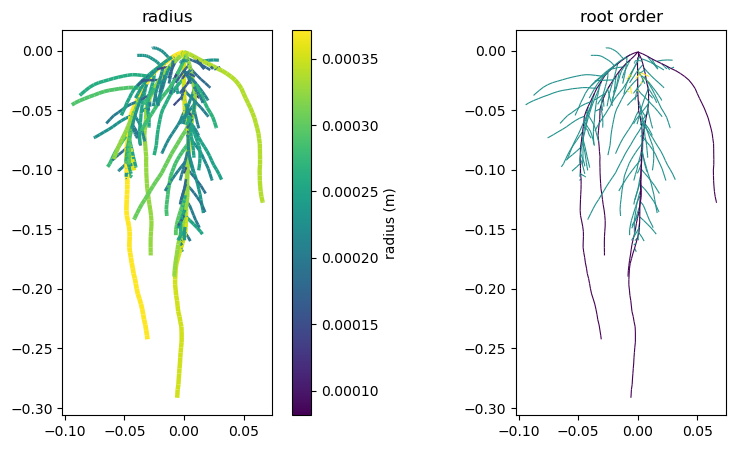

{'length': 4.242440920665556,
 'struct_mass': 0.13714376440847814,
 'living_struct_mass': 0.13714376440847842,
 'vertices': 1765,
 'apices': 885,
 'lateral_apices': 830}

In [5]:
one = Scene(planting(Architecture, [{"parameters": WHEAT}]), time_step=3600)
one.simulate(24 * 10)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
lines = draw_root_system(axes[0], record(one), color_by="radius")
fig.colorbar(lines, ax=axes[0], label="radius (m)")
draw_root_system(axes[1], record(one), color_by="root_order", linewidth_by_radius=False)
axes[0].set_title("radius"); axes[1].set_title("root order")
plt.show()
totals(record(one))

## 4. The satisfaction coefficient

Growth is the potential growth times the **satisfaction coefficient** SC, the structural mass offered to growth over the
potential growth's demand, between 0 and 1. Without an offer (the default, infinite), SC = 1.

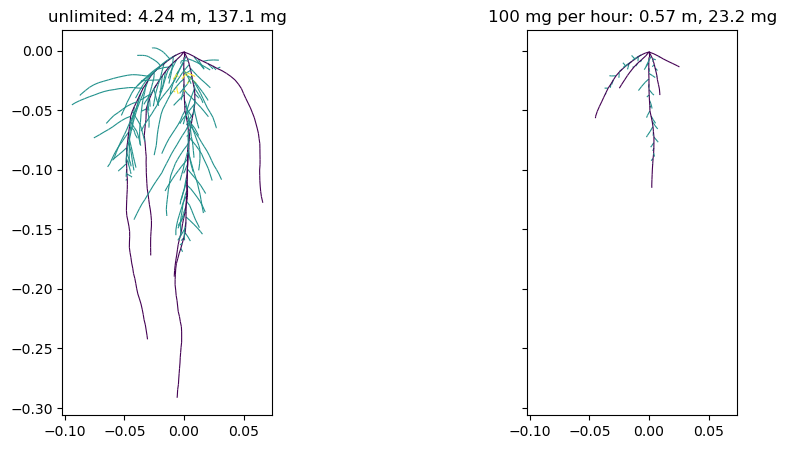

In [6]:
runs = {}
for label, offer in (("unlimited", None), ("100 mg per hour", 100e-6)):
    # a key the model names in its __init__ (offer) is its own argument; "parameters", its components'
    runs[label] = Scene(planting(Architecture, [{"parameters": WHEAT, "offer": offer}]), time_step=3600)
    runs[label].simulate(24 * 10)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (label, run) in zip(axes, runs.items()):
    draw_root_system(ax, record(run), color_by="root_order", linewidth_by_radius=False)
    t = totals(record(run))
    ax.set_title(f"{label}: {t['length']:.2f} m, {t['struct_mass'] * 1e3:.1f} mg")
plt.show()

## 5. A population in one MPG

A stand's plants are grown together: the planting table gives each its position and scenario, and one population (one
model instance, one DataStructure) holds them all, their elements in the same arrays. Each step is one call for the whole
stand. Each plant is the same as grown alone (`test/test_population.py`: bit for bit, its draws keyed by lineage). The
plants of one population differ by their numeric parameters; a switch (a boolean option) is the population's: plants with
another switch make another population.

In [7]:
from openalea.metafspm.scene.population import planting_table

n_plants, days = 16, 10
scenarios = [{"parameters": dict(WHEAT, random_choice=1 + k)} for k in range(n_plants)]    # their own draws
stand = planting_table(xrange=0.4, yrange=0.4, sowing_density=n_plants / 0.16, row_spacing=0.1,
                       plant_models=[Architecture], plant_scenarios=[scenarios[0]], per_plant_scenarios=scenarios,
                       exact=True, seed=0)
start = time.perf_counter()
population = Scene(stand, time_step=3600)
population.simulate(24 * days)
together = time.perf_counter() - start
ds = population.populations[0].data_structure
print(f"{len(ds.entity_ids('Plant'))} plants, {ds.n_nodes()} root elements in one MPG: {together:.1f} s")

start = time.perf_counter()
for scenario in scenarios:                                         # the same plants, one Scene each
    Scene(planting(Architecture, [scenario]), time_step=3600).simulate(24 * days)
one_by_one = time.perf_counter() - start
print(f"one by one: {one_by_one:.1f} s; the population {one_by_one / together:.1f} times faster")

Launching scene 'population' with 4 rows, 4 plant per rows, which represents 16 plants
16 plants, 30457 root elements in one MPG: 7.0 s
one by one: 26.1 s; the population 3.7 times faster


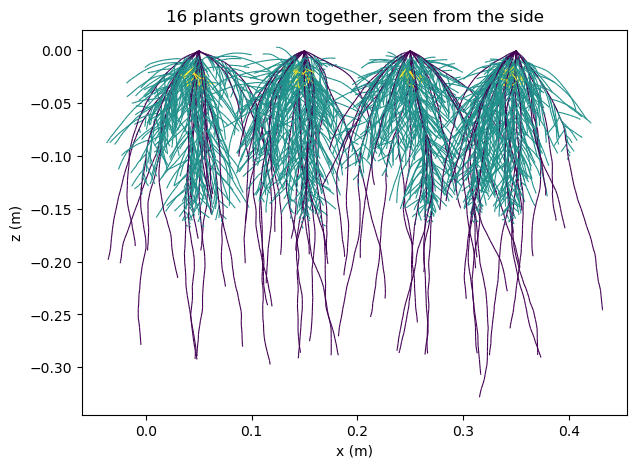

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
for plant in range(n_plants):                                       # each at its position in the row (x)
    draw_root_system(ax, record(population, plant), color_by="root_order", linewidth_by_radius=False,
                     origin=(stand.x[plant], stand.y[plant], 0.), vmin=1, vmax=3)
ax.set_title(f"{n_plants} plants grown together, seen from the side")
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)")
plt.show()

## 6. Contrasted architectures: parametrization by species

The calibrated species differ by their tip diameters (`D_ini`, `Dmin`), their elongation per diameter (`EL`), their growth
durations (`GDs`), their branching (`IPD`, `RMD`, `CVDD`), their radial growth (`SGC`) and the emission of their nodal roots
(`n_adventitious_roots`, `ER`). Each grows alone, 30 days (maize 20: its nodal roots make it the largest, 37 000 elements
at 20 days).

Above, the root orders; below, the radii (the lines' widths and colours, on one logarithmic scale for the four). Pea and
peach (dicotyledons, `SGC` 0.9) thicken their older roots by secondary growth, as the pipe model gives them (each element's
section at least its successor's plus `SGC` times its laterals'): their first-order roots' bases reach several times their
tips' diameter. Wheat and maize (monocotyledons, `SGC` 0) have none: each root keeps its tip's diameter.

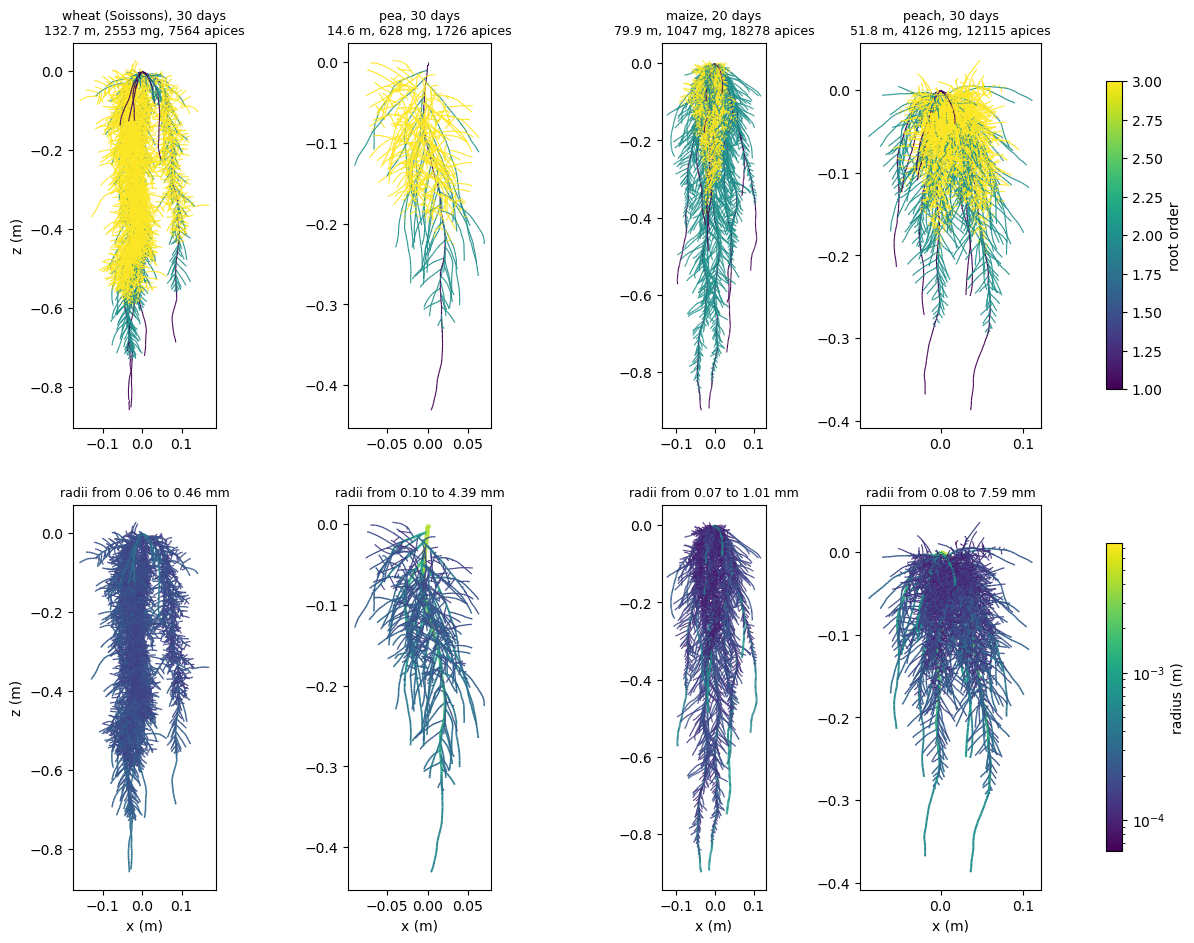

In [9]:
days = {"maize": 20}                                               # 30 days for the others
records = {}
for species, parameters in SPECIES.items():
    stand = Scene(planting(Architecture, [{"parameters": parameters}]), time_step=3600)
    stand.simulate(24 * days.get(species, 30))
    records[species] = record(stand)

# Plotting section
radii_of = {species: np.array([r.props["radius"][vertex] for vertex in r.vertices]) for species, r in records.items()}
smallest = min(radii[radii > 0].min() for radii in radii_of.values())
largest = max(radii.max() for radii in radii_of.values())
fig, axes = plt.subplots(2, len(SPECIES), figsize=(17, 11))
for column, (species, r) in enumerate(records.items()):
    orders = draw_root_system(axes[0, column], r, color_by="root_order", linewidth_by_radius=False, vmin=1, vmax=3)
    radii = draw_root_system(axes[1, column], r, color_by="radius")
    radii.set_norm(LogNorm(smallest, largest))                      # one scale for the four, logarithmic
    radii.set_linewidths(0.3 + 4. * np.sqrt(radii.get_array() / largest))
    t = totals(r)
    axes[0, column].set_title(f"{species}, {days.get(species, 30)} days\n{t['length']:.1f} m, "
                              f"{t['struct_mass'] * 1e3:.0f} mg, {t['apices']} apices", fontsize=9)
    positive = radii_of[species][radii_of[species] > 0]
    axes[1, column].set_title(f"radii from {positive.min() * 1e3:.2f} to {positive.max() * 1e3:.2f} mm", fontsize=9)
    axes[1, column].set_xlabel("x (m)")
for row in axes:
    row[0].set_ylabel("z (m)")
fig.colorbar(orders, ax=axes[0].tolist(), label="root order", shrink=0.8)
fig.colorbar(radii, ax=axes[1].tolist(), label="radius (m)", shrink=0.8)
plt.show()